# Exploratory Data Analysis (EDA)

## Airline Delay Analysis

## Objective

The objective of this notebook is to explore the cleaned airline delay dataset and understand its structure before performing detailed analysis.
Since the dataset has already been cleaned in the previous notebook, this notebook will focus only on exploratory analysis and summary inspection.

## Import Libraries

In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Load Dataset

In [6]:
file_path = "../dataset/processed/airline_delay_cleaned.csv"

df = pd.read_csv(file_path)

## Dataset Shape

In [7]:
df.shape

(1998955, 27)

In [8]:
df.isnull().sum()

Year                       0
Quarter                    0
Month                      0
DayofMonth                 0
DayOfWeek                  0
FlightDate                 0
Reporting_Airline          0
Origin                     0
OriginCityName             0
OriginState                0
Dest                       0
DestCityName               0
DestState                  0
DepDelay               36048
DepDelayMinutes        36048
ArrDelay               41052
ArrDelayMinutes        41052
CarrierDelay               0
WeatherDelay               0
NASDelay                   0
SecurityDelay              0
LateAircraftDelay          0
Cancelled                  0
CancellationCode     1978735
Diverted                   0
Distance                   0
DistanceGroup              0
dtype: int64

## First 5 Rows

In [9]:
df.head()

,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Origin,OriginCityName,OriginState,...,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,Cancelled,CancellationCode,Diverted,Distance,DistanceGroup
0,1998,1,1,2,5,1998-01-02,NW,MSP,"Minneapolis, MN",MN,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,991.0,4
1,2009,2,5,28,4,2009-05-28,FL,MKE,"Milwaukee, WI",WI,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,1066.0,5
2,2013,2,6,29,6,2013-06-29,MQ,GJT,"Grand Junction, CO",CO,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,773.0,4
3,2010,3,8,31,2,2010-08-31,DL,LAX,"Los Angeles, CA",CA,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,1979.0,8
4,2006,1,1,15,7,2006-01-15,US,EWR,"Newark, NJ",NJ,...,0.0,0.0,0.0,0.0,32.0,0.0,NaN,0.0,529.0,3


## Dataset Information

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1998955 entries, 0 to 1998954
Data columns (total 27 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Year               int64  
 1   Quarter            int64  
 2   Month              int64  
 3   DayofMonth         int64  
 4   DayOfWeek          int64  
 5   FlightDate         object 
 6   Reporting_Airline  object 
 7   Origin             object 
 8   OriginCityName     object 
 9   OriginState        object 
 10  Dest               object 
 11  DestCityName       object 
 12  DestState          object 
 13  DepDelay           float64
 14  DepDelayMinutes    float64
 15  ArrDelay           float64
 16  ArrDelayMinutes    float64
 17  CarrierDelay       float64
 18  WeatherDelay       float64
 19  NASDelay           float64
 20  SecurityDelay      float64
 21  LateAircraftDelay  float64
 22  Cancelled          float64
 23  CancellationCode   object 
 24  Diverted           float64
 25  Distance          

## Flight Operations Overview

Before analyzing delays in detail, it is important to understand the overall flight operations in the dataset. A clear view of completed, cancelled, and diverted flights helps establish the operational baseline and shows how often flights did not follow their planned schedule.

### Business Questions

- How many total flights are in the dataset?
- How many flights were completed?
- How many flights were cancelled?
- How many flights were diverted?
- What is the cancellation rate?
- What is the diversion rate?

In [11]:
# Calculate the overall flight status metrics
total_flights = len(df)
cancelled_flights = df["Cancelled"].sum()
diverted_flights = df["Diverted"].sum()

# A completed flight is one that was neither cancelled nor diverted
completed_flights = ((df["Cancelled"] == 0) & (df["Diverted"] == 0)).sum()

# Calculate cancellation and diversion rates
cancellation_rate = (cancelled_flights / total_flights) * 100
diversion_rate = (diverted_flights / total_flights) * 100

# Create a summary table
flight_overview = pd.DataFrame({
    "Metric": [
        "Total Flights",
        "Completed Flights",
        "Cancelled Flights",
        "Diverted Flights",
        "Cancellation Rate (%)",
        "Diversion Rate (%)"
    ],
    "Value": [
        total_flights,
        completed_flights,
        cancelled_flights,
        diverted_flights,
        round(cancellation_rate, 2),
        round(diversion_rate, 2)
    ]
})

flight_overview

,Metric,Value
0,Total Flights,1998955.00
1,Completed Flights,1957929.00
2,Cancelled Flights,36442.00
3,Diverted Flights,4584.00
4,Cancellation Rate (%),1.82
5,Diversion Rate (%),0.23


### Flight Status Distribution

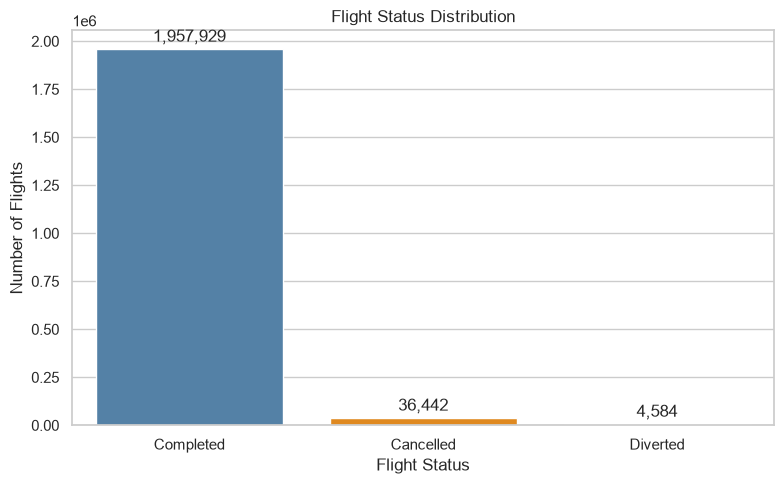

In [12]:
# Create a DataFrame to visualize the distribution of flight statuses
flight_status = pd.DataFrame({
    "Flight Status": ["Completed", "Cancelled", "Diverted"],
    "Number of Flights": [
        completed_flights,
        cancelled_flights,
        diverted_flights
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=flight_status,
    x="Flight Status",
    y="Number of Flights",
    hue="Flight Status",
    palette=["steelblue", "darkorange", "forestgreen"],
    legend=False
)

# Display the flight count above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)

plt.title("Flight Status Distribution")
plt.xlabel("Flight Status")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

### Insights

- Completed flights make up the overwhelming majority of records in the dataset.
- Cancelled flights are much fewer than completed flights, showing that cancellations are relatively uncommon.
- Diverted flights are the smallest group, indicating that diversions are rare operational events.
- The large difference between completed and disrupted flights provides a strong baseline for later delay analysis.

### Cancellation and Diversion Rates

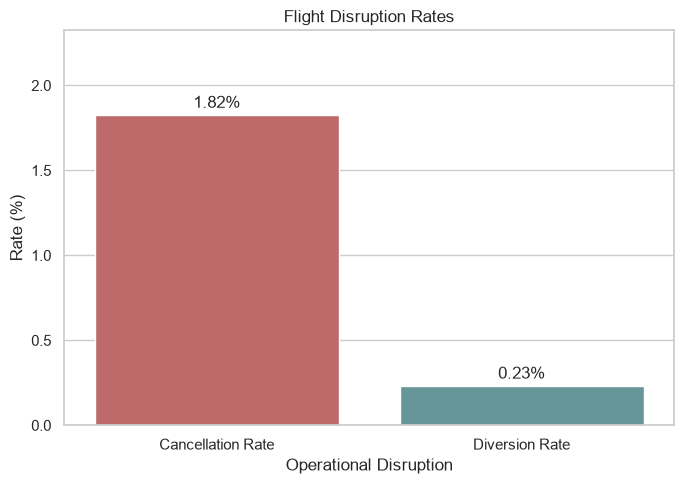

In [13]:
# Create a DataFrame to compare cancellation and diversion rates
disruption_rates = pd.DataFrame({
    "Metric": ["Cancellation Rate", "Diversion Rate"],
    "Rate (%)": [cancellation_rate, diversion_rate]
})

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=disruption_rates,
    x="Metric",
    y="Rate (%)",
    hue="Metric",
    palette=["indianred", "cadetblue"],
    legend=False
)

# Display the percentage above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Flight Disruption Rates")
plt.xlabel("Operational Disruption")
plt.ylabel("Rate (%)")
plt.ylim(0, disruption_rates["Rate (%)"].max() + 0.5)
plt.tight_layout()
plt.show()

### Insights

- The cancellation rate is about 1.82%, which means only a small share of scheduled flights were cancelled.
- The diversion rate is about 0.23%, making diversions much less frequent than cancellations.
- Cancellations are the larger operational disruption category when compared with diversions.
- Both rates are low overall, but they still represent important service reliability issues.

## Airline Analysis

Airline-level analysis helps identify which carriers contribute the most flight activity and which carriers experience higher delay pressure. This view is useful because operational patterns can differ by airline due to route network, scheduling practices, fleet usage, and airport concentration.

### Business Questions

- How many airlines are present?
- Which airlines operate the most flights?
- Which airlines have the highest average departure delay?
- Which airlines have the highest average arrival delay?

In [14]:
# Count the number of unique airlines in the dataset
airline_count = df["Reporting_Airline"].nunique()

# Calculate flight volume and average delays for each airline
airline_summary = (
    df.groupby("Reporting_Airline")
    .agg(
        total_flights=("Reporting_Airline", "size"),
        avg_departure_delay=("DepDelayMinutes", "mean"),
        avg_arrival_delay=("ArrDelayMinutes", "mean")
    )
    .reset_index()
)

print(f"Number of airlines: {airline_count}")
airline_summary.head()

Number of airlines: 33


,Reporting_Airline,total_flights,avg_departure_delay,avg_arrival_delay
0,9E,19666,11.269094,12.391459
1,AA,234206,10.337433,12.257541
2,AS,49656,8.766195,10.417299
3,B6,37638,16.285448,17.066540
4,CO,90818,9.265064,11.898972


### Airlines Operating the Most Flights

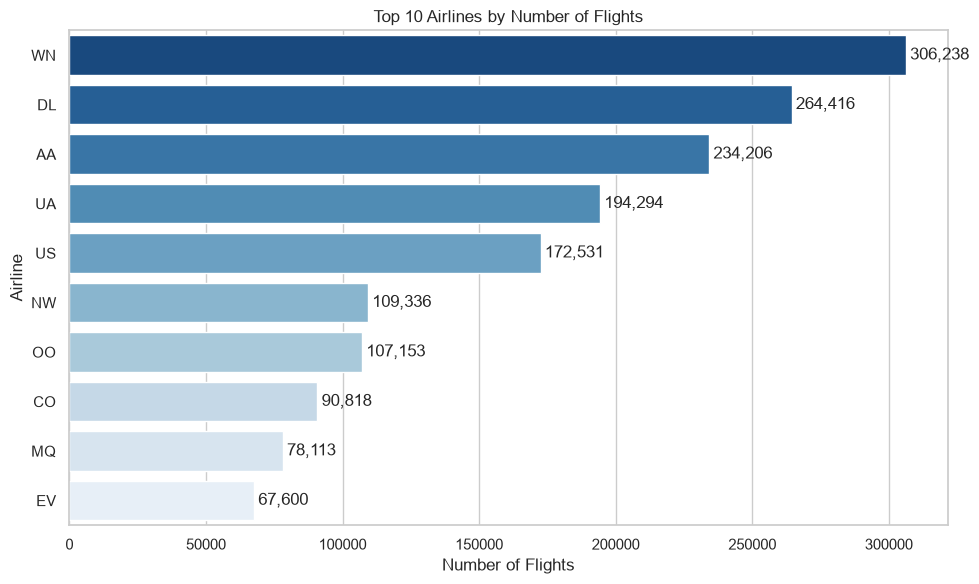

In [15]:
# Select the top 10 airlines based on the number of flights
top_airlines = (
    airline_summary
    .sort_values(by="total_flights", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_airlines,
    x="total_flights",
    y="Reporting_Airline",
    hue="Reporting_Airline",
    palette="Blues_r",
    legend=False
)

# Display the number of flights on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)

plt.title("Top 10 Airlines by Number of Flights")
plt.xlabel("Number of Flights")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

### Insights

- WN operates the highest number of flights in the dataset.
- DL, AA, and UA also have large flight volumes, making them major contributors to overall operations.
- Flight activity is concentrated among a smaller group of high-volume airlines.
- Lower-ranked airlines in the top 10 still represent meaningful operational volume.

### Airlines with Highest Average Departure Delay

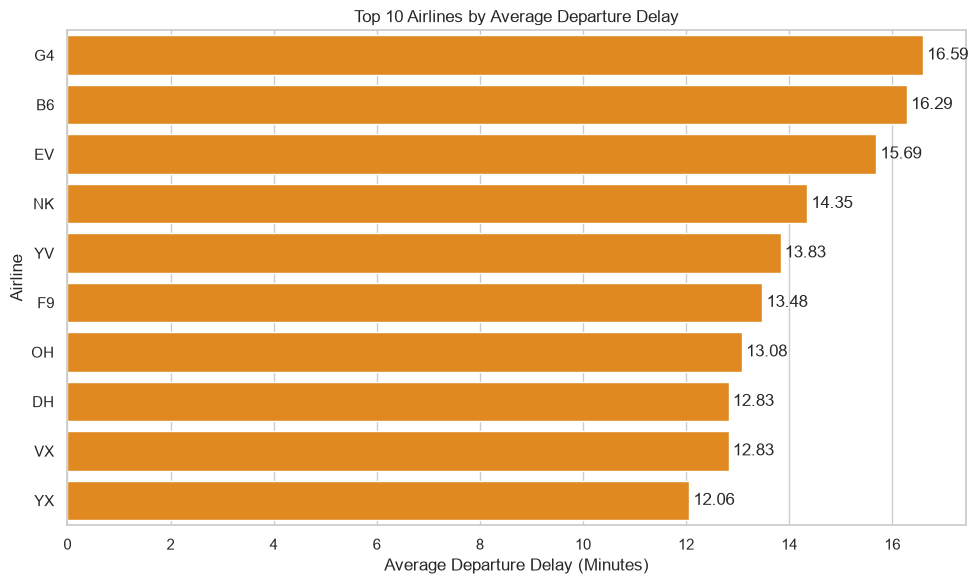

In [16]:
# Select the top 10 airlines with the highest average departure delay
top_departure_delay_airlines = (
    airline_summary
    .sort_values(by="avg_departure_delay", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_departure_delay_airlines,
    x="avg_departure_delay",
    y="Reporting_Airline",
    color="darkorange"
)

# Display the average delay on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Top 10 Airlines by Average Departure Delay")
plt.xlabel("Average Departure Delay (Minutes)")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

### Insights

- G4 has the highest average departure delay among the airlines shown.
- B6 and EV also show relatively high average departure delays.
- The top airlines in this chart have average departure delays above 12 minutes.
- Departure delay pressure is not limited to one airline, suggesting variation in operational performance across carriers.

### Airlines with Highest Average Arrival Delay

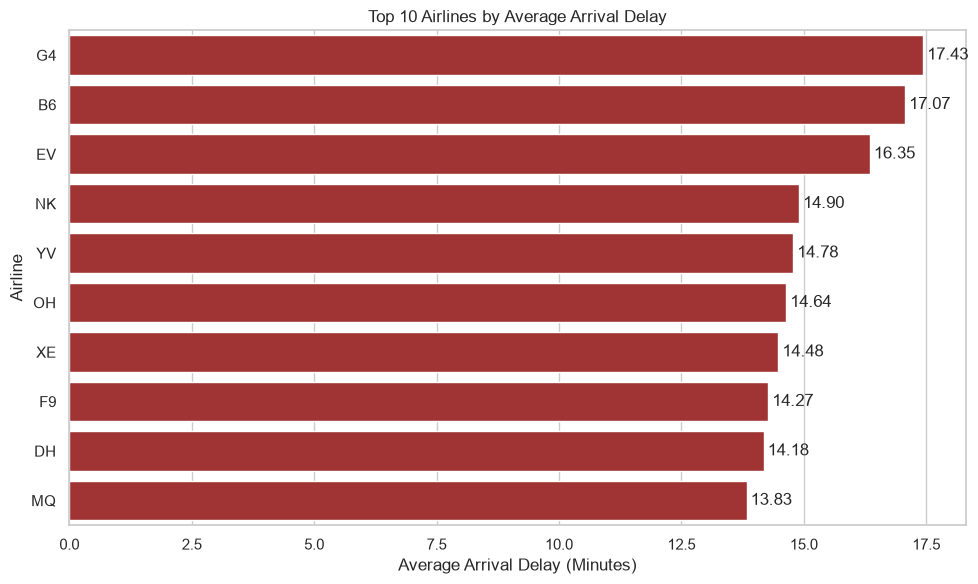

In [17]:
# Select the top 10 airlines with the highest average arrival delay
top_arrival_delay_airlines = (
    airline_summary
    .sort_values(by="avg_arrival_delay", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_arrival_delay_airlines,
    x="avg_arrival_delay",
    y="Reporting_Airline",
    color="firebrick"
)

# Display the average delay on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Top 10 Airlines by Average Arrival Delay")
plt.xlabel("Average Arrival Delay (Minutes)")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

### Insights

- G4 has the highest average arrival delay among the airlines shown.
- B6 and EV remain near the top, indicating that higher delay levels continue through arrival.
- XE appears in the arrival delay ranking, showing stronger arrival delay impact than departure delay ranking.
- The highest average arrival delays are slightly above the highest average departure delays.

## Airport Analysis

Airport-level analysis helps identify where flight activity is concentrated and where delays are more likely to occur. Airports can create bottlenecks through congestion, weather exposure, runway limits, and gate availability, so reviewing airport performance is important before deeper delay analysis.

### Business Questions

- Which origin airports handle the most flights?
- Which destination airports handle the most flights?
- Which airports experience the highest average departure delay?
- Which airports experience the highest average arrival delay?

In [18]:
# Calculate flight volume and average departure delay for each origin airport
origin_airport_summary = (
    df.groupby("Origin")
    .agg(
        total_flights=("Origin", "size"),
        avg_departure_delay=("DepDelayMinutes", "mean")
    )
    .reset_index()
)

# Calculate flight volume and average arrival delay for each destination airport
destination_airport_summary = (
    df.groupby("Dest")
    .agg(
        total_flights=("Dest", "size"),
        avg_arrival_delay=("ArrDelayMinutes", "mean")
    )
    .reset_index()
)

# Minimum number of flights required to include an airport in delay analysis
min_flights = 10000

### Origin Airports Handling the Most Flights

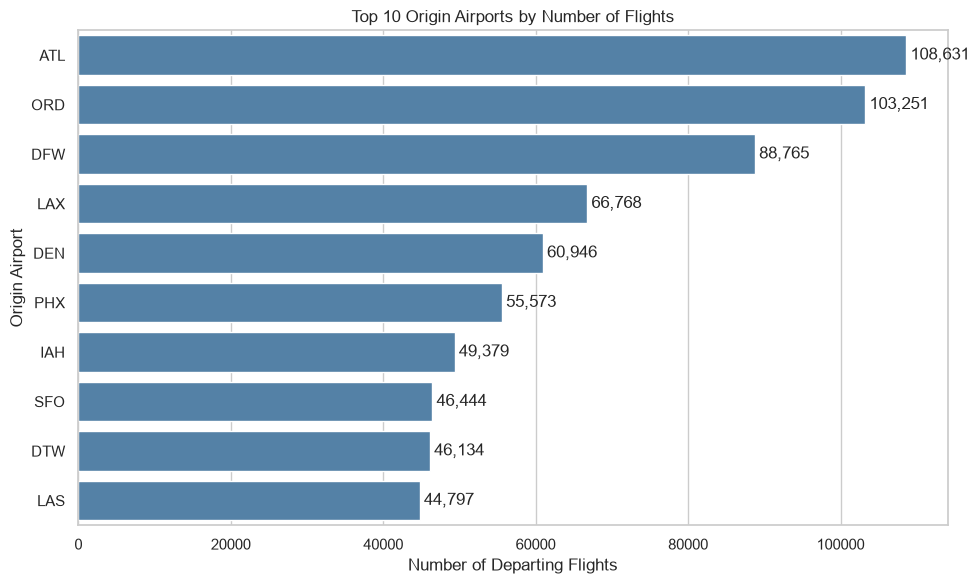

In [19]:
# Select the top 10 origin airports by flight volume
top_origin_airports = (
    origin_airport_summary
    .sort_values(by="total_flights", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_origin_airports,
    x="total_flights",
    y="Origin",
    color="steelblue"
)

# Display the number of flights on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)

plt.title("Top 10 Origin Airports by Number of Flights")
plt.xlabel("Number of Departing Flights")
plt.ylabel("Origin Airport")
plt.tight_layout()
plt.show()

### Insights

- ATL handles the highest number of departing flights in the dataset.
- ORD and DFW are also major origin airports with very high departure volume.
- The top origin airports are large hub airports, which means they have strong influence on overall network operations.
- LAX, DEN, PHX, IAH, SFO, DTW, and LAS form the next tier of high-volume origin airports.

### Destination Airports Handling the Most Flights

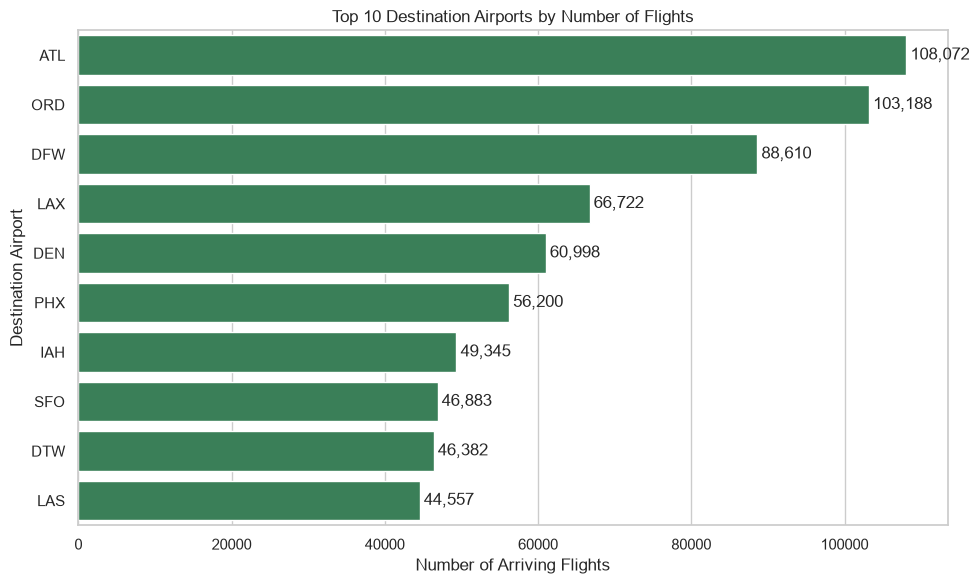

In [20]:
# Select the top 10 destination airports by flight volume
top_destination_airports = (
    destination_airport_summary
    .sort_values(by="total_flights", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_destination_airports,
    x="total_flights",
    y="Dest",
    color="seagreen"
)

# Display the number of flights on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)

plt.title("Top 10 Destination Airports by Number of Flights")
plt.xlabel("Number of Arriving Flights")
plt.ylabel("Destination Airport")
plt.tight_layout()
plt.show()

### Insights

- ATL is also the busiest destination airport in the dataset.
- ORD and DFW remain the next highest-volume destination airports.
- The destination volume ranking closely matches the origin volume ranking, showing balanced activity at major hubs.
- PHX has slightly more arriving flights than DEN in this ranking.

### Airports with Highest Average Departure Delay

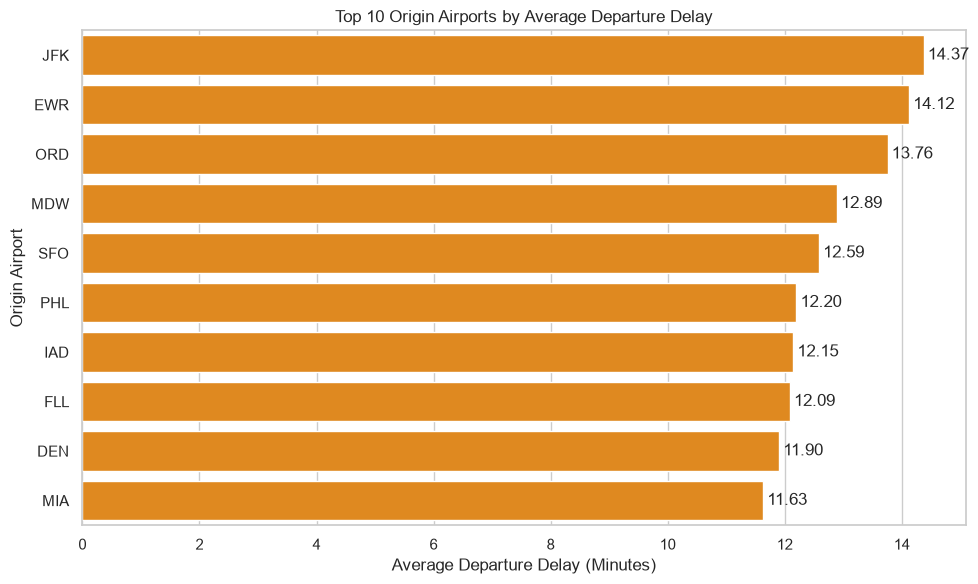

In [21]:
# Select the top 10 origin airports with the highest average departure delay
top_departure_delay_airports = (
    origin_airport_summary
    .query("total_flights >= @min_flights")
    .sort_values(by="avg_departure_delay", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_departure_delay_airports,
    x="avg_departure_delay",
    y="Origin",
    color="darkorange"
)

# Display the average delay on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Top 10 Origin Airports by Average Departure Delay")
plt.xlabel("Average Departure Delay (Minutes)")
plt.ylabel("Origin Airport")
plt.tight_layout()
plt.show()

### Insights

- JFK has the highest average departure delay among airports with at least 10,000 departing flights.
- EWR and ORD also show high average departure delays, placing them near the top of the ranking.
- Several large metropolitan airports appear in this chart, including JFK, EWR, ORD, MDW, SFO, and PHL.
- The highest average departure delays are clustered around 12 to 14 minutes.

### Airports with Highest Average Arrival Delay

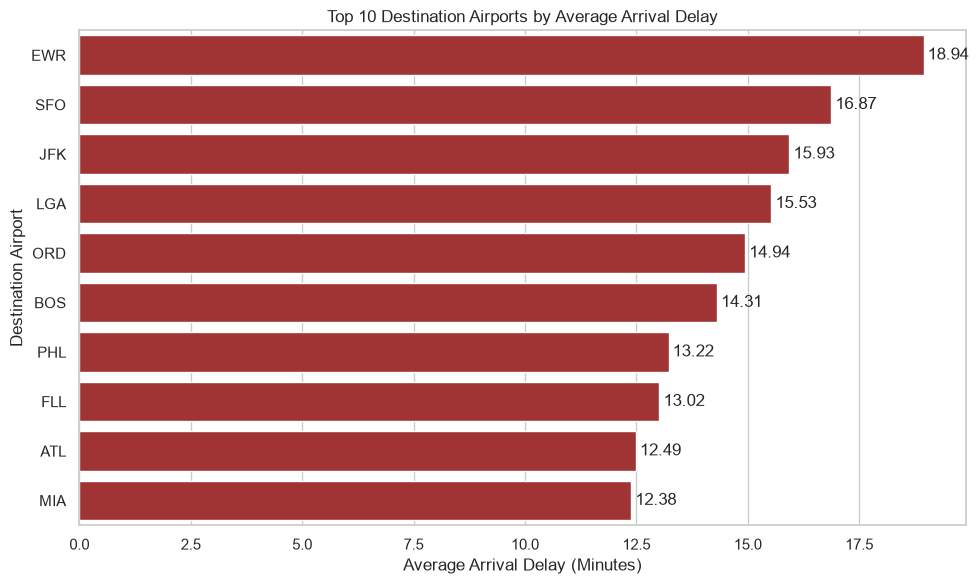

In [22]:
# Select the top 10 destination airports with the highest average arrival delay
top_arrival_delay_airports = (
    destination_airport_summary
    .query("total_flights >= @min_flights")
    .sort_values(by="avg_arrival_delay", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_arrival_delay_airports,
    x="avg_arrival_delay",
    y="Dest",
    color="firebrick"
)

# Display the average delay on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Top 10 Destination Airports by Average Arrival Delay")
plt.xlabel("Average Arrival Delay (Minutes)")
plt.ylabel("Destination Airport")
plt.tight_layout()
plt.show()

### Insights

- EWR has the highest average arrival delay among airports with at least 10,000 arriving flights.
- SFO and JFK also show high average arrival delays, indicating stronger arrival-side delay pressure.
- New York-area airports appear repeatedly in the arrival delay ranking.
- Arrival delays at the top airports are higher than the top average departure delays shown earlier.

## Delay Analysis

This section analyzes departure and arrival delay patterns using average delay, median delay, distributions, and outliers. The goal is to understand whether delays are common across most flights or concentrated in a smaller group of severe delay cases.

In [23]:
# Compare the average and median delay for departures and arrivals
avg_departure_delay = df["DepDelayMinutes"].mean()
avg_arrival_delay = df["ArrDelayMinutes"].mean()

median_departure_delay = df["DepDelayMinutes"].median()
median_arrival_delay = df["ArrDelayMinutes"].median()

delay_summary = pd.DataFrame({
    "Delay Type": ["Departure Delay", "Arrival Delay"],
    "Average Delay (Minutes)": [
        avg_departure_delay,
        avg_arrival_delay
    ],
    "Median Delay (Minutes)": [
        median_departure_delay,
        median_arrival_delay
    ]
})

delay_summary.round(2)

,Delay Type,Average Delay (Minutes),Median Delay (Minutes)
0,Departure Delay,10.50,0.0
1,Arrival Delay,11.79,0.0


In [24]:
def calculate_outlier_summary(df, delay_column):
    """
    Calculate IQR-based outlier statistics for a delay column.
    """

    # Calculate the quartiles and interquartile range
    q1 = df[delay_column].quantile(0.25)
    q3 = df[delay_column].quantile(0.75)
    iqr = q3 - q1

    # Calculate the upper limit for identifying outliers
    upper_limit = q3 + (1.5 * iqr)

    # Count observations beyond the upper limit
    outlier_count = (df[delay_column] > upper_limit).sum()
    total_flights = df[delay_column].notna().sum()

    outlier_rate = (outlier_count / total_flights) * 100

    return pd.Series({
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Upper Outlier Limit": upper_limit,
        "Outlier Count": outlier_count,
        "Outlier Rate (%)": outlier_rate
    })


# Generate the outlier summary for departure and arrival delays
outlier_summary = pd.DataFrame({
    "Departure Delay": calculate_outlier_summary(df, "DepDelayMinutes"),
    "Arrival Delay": calculate_outlier_summary(df, "ArrDelayMinutes")
}).T

outlier_summary.round(2)

,Q1,Q3,IQR,Upper Outlier Limit,Outlier Count,Outlier Rate (%)
Departure Delay,0.0,7.0,7.0,17.5,293447.0,14.95
Arrival Delay,0.0,10.0,10.0,25.0,247938.0,12.66


### Departure Delay Distribution

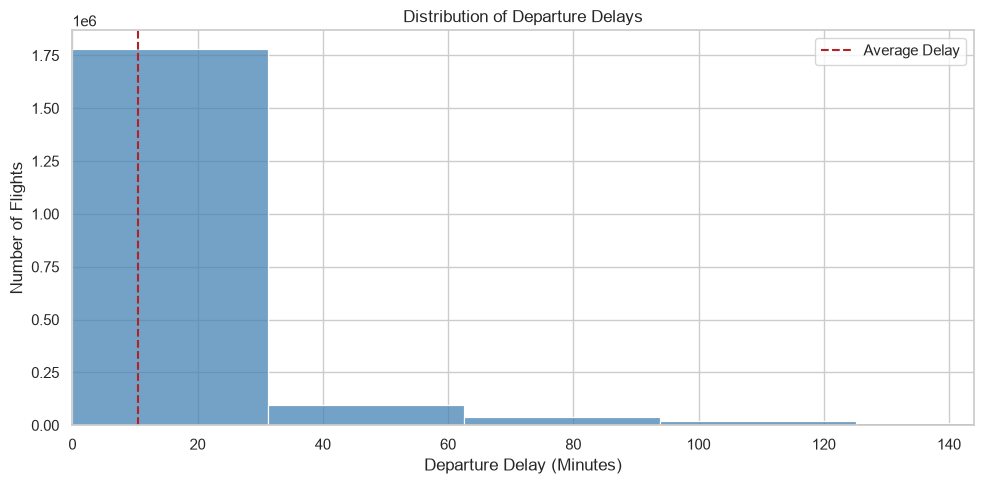

In [25]:
# Calculate the average departure delay
mean_departure_delay = df["DepDelayMinutes"].mean()

plt.figure(figsize=(10, 5))

# Plot the distribution of departure delays
sns.histplot(
    df["DepDelayMinutes"],
    bins=60,
    color="steelblue"
)

# Mark the average departure delay
plt.axvline(
    mean_departure_delay,
    color="firebrick",
    linestyle="--",
    label="Average Delay"
)

plt.title("Distribution of Departure Delays")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.xlim(0, df["DepDelayMinutes"].quantile(0.99))
plt.legend()
plt.tight_layout()
plt.show()

### Insights

- Most departure delays are concentrated near 0 minutes.
- The median departure delay is 0 minutes, showing that at least half of flights departed on time or without positive delay minutes.
- The average departure delay is higher than the median, which indicates a right-skewed distribution.
- A smaller number of longer delays stretches the distribution to the right.

### Arrival Delay Distribution

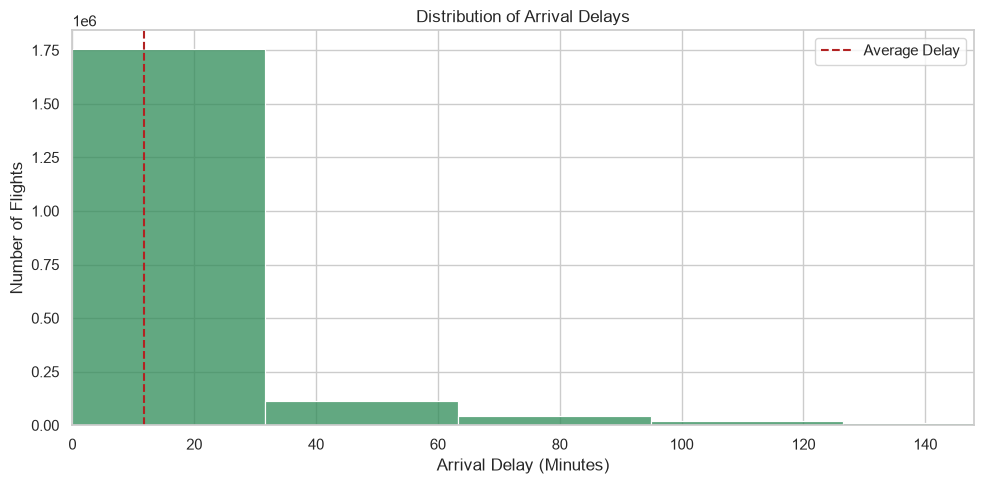

In [26]:
# Calculate the average arrival delay
mean_arrival_delay = df["ArrDelayMinutes"].mean()

plt.figure(figsize=(10, 5))

# Plot the distribution of arrival delays
sns.histplot(
    df["ArrDelayMinutes"],
    bins=60,
    color="seagreen"
)

# Mark the average arrival delay
plt.axvline(
    mean_arrival_delay,
    color="firebrick",
    linestyle="--",
    label="Average Delay"
)

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.xlim(0, df["ArrDelayMinutes"].quantile(0.99))
plt.legend()
plt.tight_layout()
plt.show()

### Insights

- Arrival delays are also heavily concentrated near 0 minutes.
- The median arrival delay is 0 minutes, meaning most flights did not have meaningful positive arrival delay minutes.
- The average arrival delay is higher than the median, showing that longer delayed arrivals pull the average upward.
- The distribution has a visible right tail, indicating that severe arrival delays occur for a smaller subset of flights.

### Departure Delay Outliers

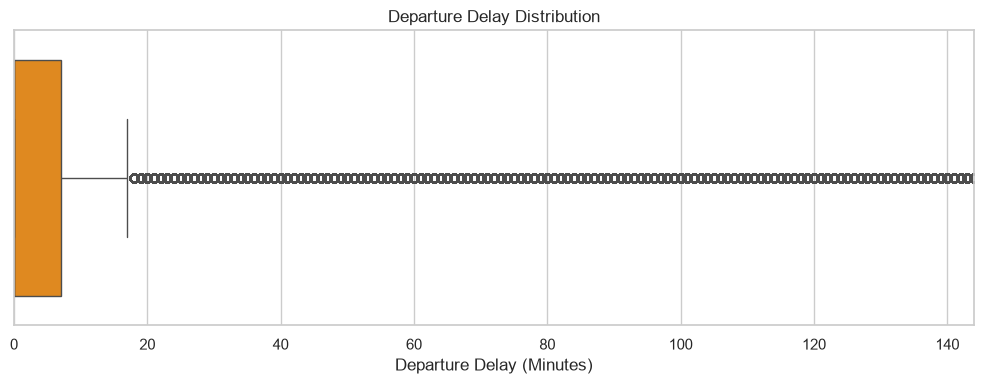

In [27]:
# Visualize outliers in departure delays
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="DepDelayMinutes",
    color="darkorange"
)

plt.title("Departure Delay Distribution")
plt.xlabel("Departure Delay (Minutes)")

# Limit the x-axis to improve readability
plt.xlim(0, df["DepDelayMinutes"].quantile(0.99))

plt.tight_layout()
plt.show()

### Insights

- Departure delay outliers begin above about 17.5 minutes using the IQR rule.
- Around 14.95% of flights are flagged as departure delay outliers by this method.
- The boxplot shows many points beyond the main spread, confirming that longer departure delays are not evenly distributed.
- The long right-side pattern suggests that severe departure delays are important even if most flights are close to on time.

### Arrival Delay Outliers

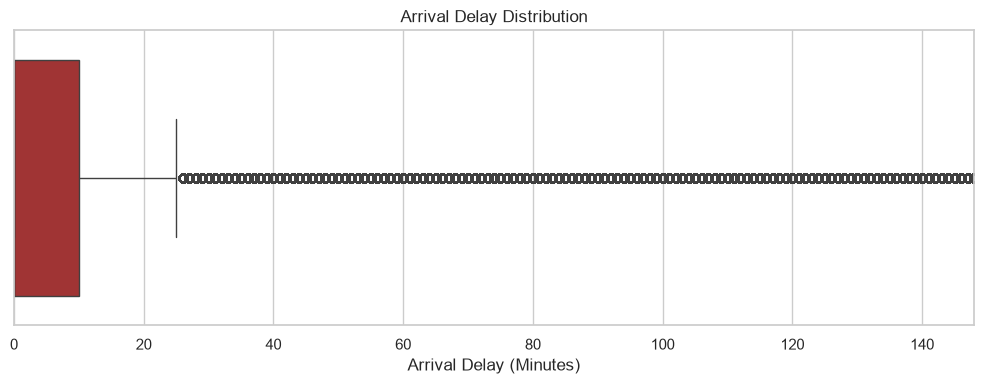

In [28]:
# Visualize outliers in arrival delays
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="ArrDelayMinutes",
    color="firebrick"
)

plt.title("Arrival Delay Distribution")
plt.xlabel("Arrival Delay (Minutes)")

# Limit the x-axis to improve readability
plt.xlim(0, df["ArrDelayMinutes"].quantile(0.99))

plt.tight_layout()
plt.show()

### Insights

- Arrival delay outliers begin above about 25 minutes using the IQR rule.
- Around 12.66% of flights are flagged as arrival delay outliers by this method.
- The outlier spread shows that a minority of flights experience much longer arrival delays.
- Arrival delay outliers extend farther than the central range, which can strongly affect average delay performance.

## Delay Cause Analysis

This section analyzes the main reported causes of delay: carrier, weather, National Air System, security, and late aircraft delay. Comparing total delay minutes, average delay minutes, and frequency helps identify which causes create the largest operational burden.

### Business Questions

- Which delay type contributes the highest total delay?
- Which delay type has the highest average delay?
- Which delay type occurs most frequently?

In [29]:
# Select the delay-related columns
delay_columns = [
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

# Display names for each delay type
delay_labels = {
    "CarrierDelay": "Carrier Delay",
    "WeatherDelay": "Weather Delay",
    "NASDelay": "NAS Delay",
    "SecurityDelay": "Security Delay",
    "LateAircraftDelay": "Late Aircraft Delay"
}

# Create a subset containing only the delay columns
delay_data = df[delay_columns]

# Summarize each delay type
delay_cause_summary = pd.DataFrame({
    "Delay Cause": [delay_labels[col] for col in delay_columns],
    "Total Delay Minutes": delay_data.sum().values,
    "Frequency": (delay_data > 0).sum().values,
    "Frequency Rate (%)": (delay_data > 0).mean().values * 100
})

delay_cause_summary.round(2)

,Delay Cause,Total Delay Minutes,Frequency,Frequency Rate (%)
0,Carrier Delay,3746825.0,104612,5.23
1,Weather Delay,652085.0,13896,0.70
2,NAS Delay,3413414.0,126814,6.34
3,Security Delay,18825.0,927,0.05
4,Late Aircraft Delay,4891681.0,108492,5.43


### Total Delay Minutes by Cause

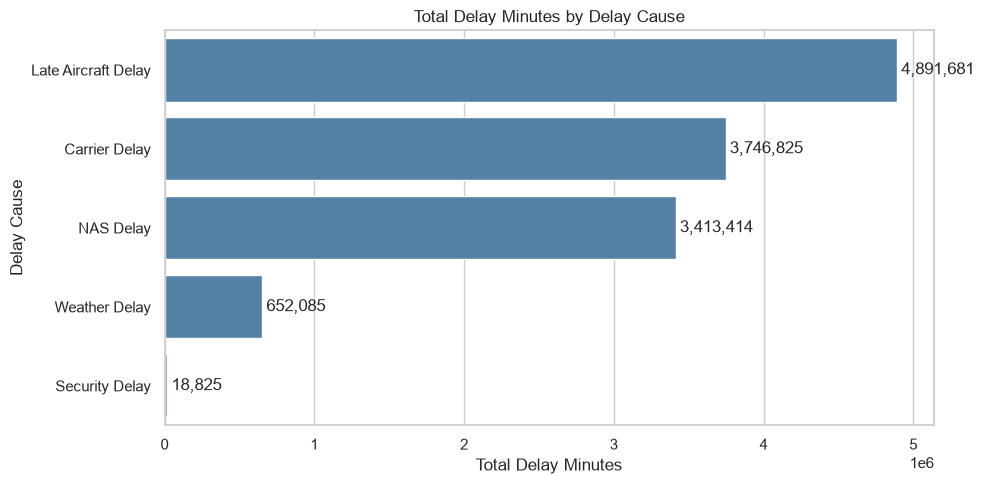

In [30]:
# Sort delay causes by total delay minutes
total_delay_by_cause = delay_cause_summary.sort_values(
    by="Total Delay Minutes",
    ascending=False
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=total_delay_by_cause,
    x="Total Delay Minutes",
    y="Delay Cause",
    color="steelblue"
)

# Display the total delay on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)

plt.title("Total Delay Minutes by Delay Cause")
plt.xlabel("Total Delay Minutes")
plt.ylabel("Delay Cause")
plt.tight_layout()
plt.show()

### Insights

- Late aircraft delay contributes the highest total delay minutes.
- Carrier delay and NAS delay are also major contributors to total delay time.
- Weather delay contributes far fewer total minutes than the top three causes.
- Security delay has the smallest total delay contribution.

### Delay Cause Frequency

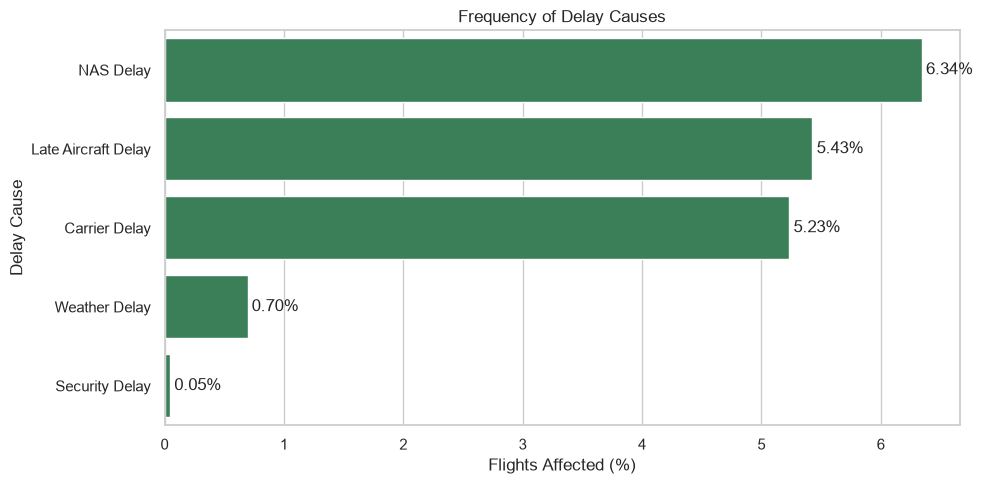

In [31]:
# Sort delay causes by frequency rate
delay_frequency = delay_cause_summary.sort_values(
    by="Frequency Rate (%)",
    ascending=False
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=delay_frequency,
    x="Frequency Rate (%)",
    y="Delay Cause",
    color="seagreen"
)

# Display the frequency rate on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Frequency of Delay Causes")
plt.xlabel("Flights Affected (%)")
plt.ylabel("Delay Cause")
plt.tight_layout()
plt.show()

### Insights

- NAS delay is the most common delay type, affecting the highest percentage of flights.
- Carrier delay and late aircraft delay are also frequent, indicating that operational factors contribute significantly to flight delays.
- Weather delay affects a smaller proportion of flights compared to operational delay causes.
- Security delay is the least frequent, suggesting it has minimal impact on overall flight disruptions.

## Cancellation Analysis

Cancellation analysis helps measure how often scheduled flights did not operate and why those cancellations occurred. Although cancellations are less frequent than delays, they usually create stronger passenger disruption and require separate operational attention.

### Business Questions

- How many flights were cancelled?
- What are the most common cancellation reasons?
- What percentage of flights were cancelled?

In [38]:
# Calculate the overall flight cancellation statistics
total_flights = len(df)
cancelled_flights = df["Cancelled"].sum()
cancellation_rate = (cancelled_flights / total_flights) * 100

# Create a summary table
cancellation_summary = pd.DataFrame({
    "Metric": [
        "Total Flights",
        "Cancelled Flights",
        "Cancellation Rate (%)"
    ],
    "Value": [
        total_flights,
        int(cancelled_flights),
        round(cancellation_rate, 2)
    ]
})

cancellation_summary

,Metric,Value
0,Total Flights,1998955.00
1,Cancelled Flights,36442.00
2,Cancellation Rate (%),1.82


### Cancellation Status

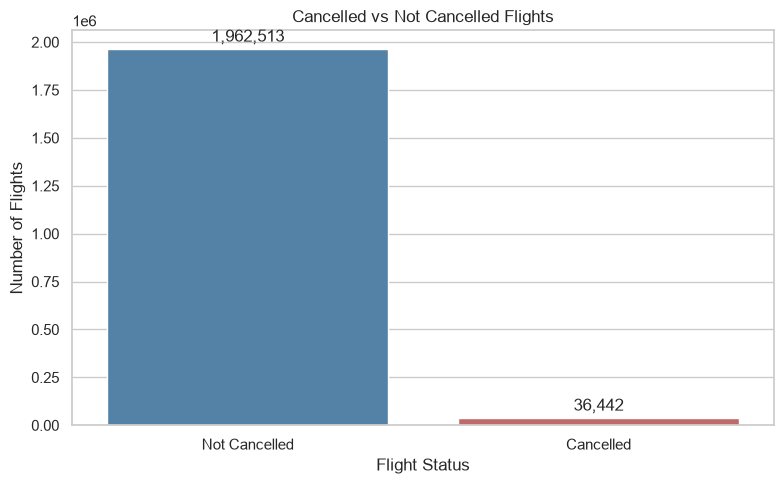

In [39]:
# Calculate the number of cancelled and non-cancelled flights
cancellation_status = pd.DataFrame({
    "Status": ["Not Cancelled", "Cancelled"],
    "Number of Flights": [
        total_flights - cancelled_flights,
        cancelled_flights
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=cancellation_status,
    x="Status",
    y="Number of Flights",
    hue="Status",
    palette=["steelblue", "indianred"],
    legend=False
)

# Display the number of flights on each bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)

plt.title("Cancelled vs Not Cancelled Flights")
plt.xlabel("Flight Status")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

### Insights

- Most flights in the dataset were not cancelled.
- Cancelled flights account for a small share of total flight records.
- The large gap between cancelled and not cancelled flights shows that cancellations are uncommon compared with normal operations.
- Even with a low count share, cancellations remain important because they fully interrupt planned travel.

### Cancellation Reasons

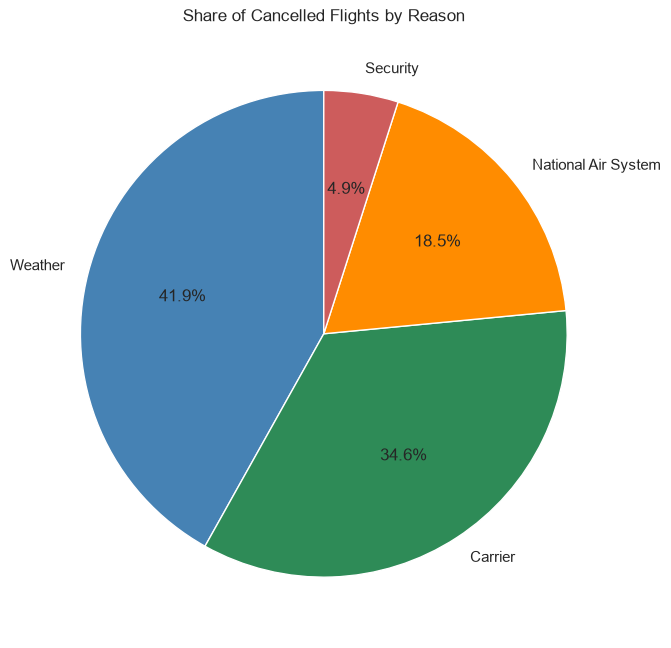

In [41]:
# Cancellation code definitions are based on the official
# U.S. Bureau of Transportation Statistics (BTS) documentation.
cancellation_reason_map = {
    "A": "Carrier",
    "B": "Weather",
    "C": "National Air System",
    "D": "Security"
}

# Select only cancelled flights
cancelled_flights_df = df[df["Cancelled"] == 1].copy()

# Map cancellation codes to their corresponding reasons
cancelled_flights_df["Cancellation Reason"] = (
    cancelled_flights_df["CancellationCode"]
    .map(cancellation_reason_map)
)

# Keep only flights with known cancellation reasons
cancelled_flights_df = cancelled_flights_df.dropna(
    subset=["Cancellation Reason"]
)

# Count cancelled flights by reason
cancellation_reasons = (
    cancelled_flights_df["Cancellation Reason"]
    .value_counts()
)

plt.figure(figsize=(7, 7))

plt.pie(
    cancellation_reasons,
    labels=cancellation_reasons.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "seagreen", "darkorange", "indianred"],
    wedgeprops={"edgecolor": "white"}
)

plt.title("Share of Cancelled Flights by Reason")
plt.tight_layout()
plt.show()

### Insights

- Based on the official U.S. Bureau of Transportation Statistics (BTS) cancellation code definitions, weather is the most common recorded cancellation reason.
- Carrier-related cancellations are the second most common recorded reason.
- National Air System cancellations occur less frequently than weather and carrier-related cancellations.
- Security-related cancellations are the least common recorded reason.


### Business Interpretation

Cancellation metrics show that cancellations are relatively uncommon, but they represent a serious reliability issue because each cancelled flight directly disrupts passengers and operations. The high number of unknown cancellation reasons also suggests that reason-code completeness should be reviewed, while weather and carrier-related cancellations should receive attention as the most common known causes.

## Time-based Analysis

Time-based analysis helps identify whether delays follow seasonal or weekly patterns. Understanding these patterns can support better staffing, scheduling, and disruption planning during periods with higher delay pressure.

### Business Questions

- Which months experience higher average delays?
- Which days of the week experience higher delays?
- Are there any noticeable seasonal or weekly trends?

In [35]:
# Map month and weekday numbers to their names
month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

day_names = {
    1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu",
    5: "Fri", 6: "Sat", 7: "Sun"
}

# Summarize flight delays by month
monthly_delay_summary = (
    df.groupby(by="Month")
    .agg(
        avg_departure_delay=("DepDelayMinutes", "mean"),
        avg_arrival_delay=("ArrDelayMinutes", "mean"),
        total_flights=("Month", "size")
    )
    .reset_index()
)

monthly_delay_summary["Month Name"] = (
    monthly_delay_summary["Month"].map(month_names)
)

# Summarize flight delays by day of the week
weekly_delay_summary = (
    df.groupby(by="DayOfWeek")
    .agg(
        avg_departure_delay=("DepDelayMinutes", "mean"),
        avg_arrival_delay=("ArrDelayMinutes", "mean"),
        total_flights=("DayOfWeek", "size")
    )
    .reset_index()
)

weekly_delay_summary["Day Name"] = (
    weekly_delay_summary["DayOfWeek"].map(day_names)
)

### Average Delay by Month

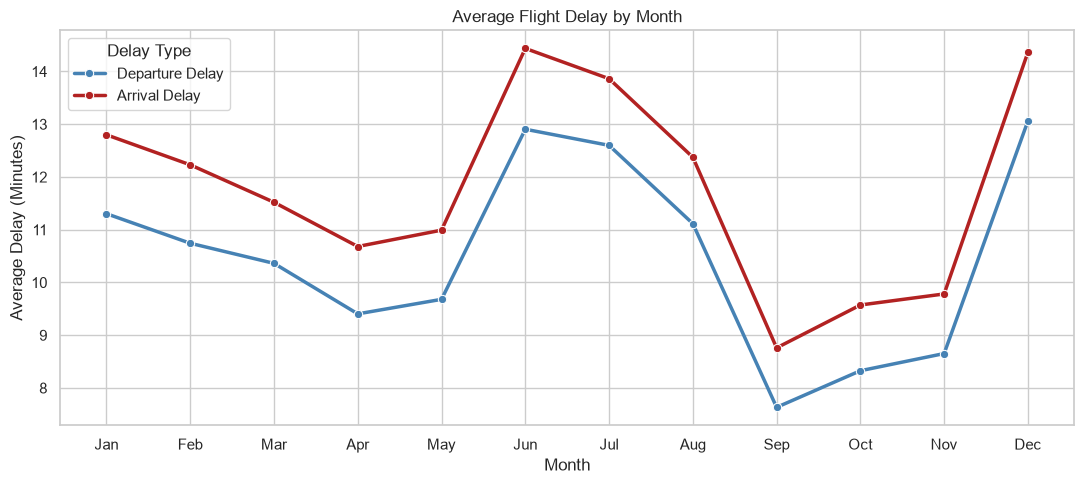

In [36]:
# Reshape the monthly summary for plotting
monthly_delay_long = monthly_delay_summary.melt(
    id_vars=["Month", "Month Name"],
    value_vars=["avg_departure_delay", "avg_arrival_delay"],
    var_name="Delay Type",
    value_name="Average Delay (Minutes)"
)

monthly_delay_long["Delay Type"] = monthly_delay_long["Delay Type"].map({
    "avg_departure_delay": "Departure Delay",
    "avg_arrival_delay": "Arrival Delay"
})

plt.figure(figsize=(11, 5))

# Plot the monthly delay trend
sns.lineplot(
    data=monthly_delay_long,
    x="Month Name",
    y="Average Delay (Minutes)",
    hue="Delay Type",
    marker="o",
    linewidth=2.5,
    palette=["steelblue", "firebrick"]
)

plt.title("Average Flight Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average Delay (Minutes)")
plt.tight_layout()
plt.show()

### Insights

- December and June show the highest average departure delays.
- June and December also show the highest average arrival delays.
- September has the lowest average delays for both departure and arrival.
- Delay levels rise during summer and winter peak periods, then ease in early fall.

### Average Delay by Day of Week

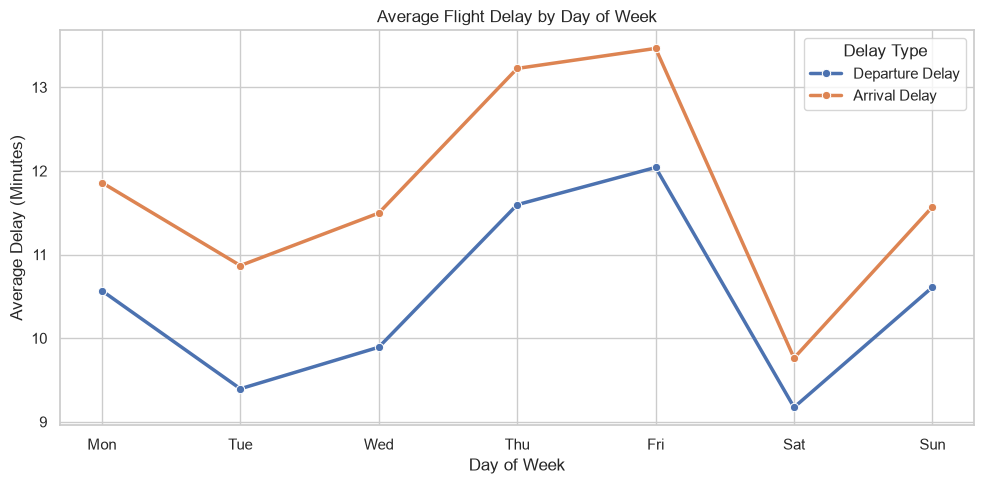

In [37]:
# Reshape the weekly summary for plotting
weekly_delay_long = weekly_delay_summary.melt(
    id_vars=["DayOfWeek", "Day Name"],
    value_vars=["avg_departure_delay", "avg_arrival_delay"],
    var_name="Delay Type",
    value_name="Average Delay (Minutes)"
)

weekly_delay_long["Delay Type"] = weekly_delay_long["Delay Type"].map({
    "avg_departure_delay": "Departure Delay",
    "avg_arrival_delay": "Arrival Delay"
})

plt.figure(figsize=(10, 5))

# Plot the weekly delay trend
sns.lineplot(
    data=weekly_delay_long,
    x="Day Name",
    y="Average Delay (Minutes)",
    hue="Delay Type",
    marker="o",
    linewidth=2.5
)

plt.title("Average Flight Delay by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Delay (Minutes)")
plt.tight_layout()
plt.show()

#### Insights

- Friday has the highest average departure delay.
- Friday and Thursday show the highest average arrival delays.
- Saturday has the lowest average delays for both departure and arrival.
- Delays are generally higher toward the end of the workweek than on Tuesday, Wednesday, or Saturday.

# Conclusion

## Key Findings

- Most flights were completed successfully, with only a small percentage being cancelled or diverted.
- A few airlines and airports handled a large share of total flights, indicating concentrated traffic across major hubs.
- Departure and arrival delays showed similar trends across airlines, airports, months, and days of the week.
- Delay distributions were right-skewed, with most flights experiencing little or no delay while a small number faced significant delays.
- NAS (National Air System) delay was the most frequent delay type, affecting the highest percentage of flights.
- Late aircraft and carrier delays contributed the largest share of total delay minutes, highlighting operational challenges.
- Flight delays varied throughout the year, indicating that seasonal factors influence airline performance.
- Most flight cancellations were caused by carrier, weather, and National Air System-related issues, while security-related cancellations were relatively rare.



## Business Interpretation

The exploratory analysis shows that flight operations are generally reliable, with most flights being completed successfully and only a small percentage resulting in cancellations or diversions. However, operational performance varies across airlines, airports, and time periods, indicating that delays are influenced by multiple operational and external factors rather than a single cause.

A relatively small number of airlines and airports handle a large proportion of total flights, making their operational efficiency critical to overall network performance. Airlines and airports with consistently higher average delays may benefit from improvements in scheduling, turnaround processes, congestion management, and resource allocation.

Delay analysis reveals that while most flights experience little or no delay, a smaller number of flights incur substantial delays that significantly increase the overall average. This suggests that reducing severe delay events could have a greater impact on improving operational performance than focusing only on routine delays.

Among the identified delay causes, **Late Aircraft**, **Carrier**, and **National Air System (NAS)** delays have the greatest operational impact. Late Aircraft delays contribute the highest overall delay time, while NAS delays affect the largest number of flights, highlighting the importance of efficient aircraft scheduling, airport operations, and coordination with air traffic management.

Although cancellations occur relatively infrequently, they have a significant impact on passengers and airline operations. The presence of unknown cancellation reasons also indicates an opportunity to improve data quality and reporting, enabling more accurate operational analysis and decision-making.

Finally, the analysis identifies clear seasonal and weekly patterns in flight delays, with higher delays occurring during peak travel months and towards the end of the work week. These trends can support better planning of staffing, airport resources, scheduling buffers, and passenger communication during periods of increased operational demand.

Overall, the findings demonstrate how data analysis can be used to identify operational bottlenecks, understand delay patterns, and support data-driven decisions aimed at improving airline efficiency, reducing disruptions, and enhancing the overall passenger experience.

## Recommendations

- Improve aircraft scheduling and turnaround efficiency to reduce late aircraft delays.
- Strengthen coordination with airport and air traffic management to minimize National Air System delays.
- Use historical delay trends to allocate additional staff and resources during high-delay periods.
- Monitor airline and airport performance regularly to identify routes or operations with persistent delays.
- Improve weather monitoring and contingency planning to reduce weather-related disruptions.
- Apply predictive analytics to identify flights at high risk of delay and take preventive actions.
- Share operational insights with airlines and airport authorities to support data-driven decision-making.